# Education: lunch eligibility and ACT scores

**Question:** How does the association between free/reduced-price lunch eligibility and school-average ACT-equivalent scores vary across states represented in the EdGap data?

This notebook prepares the assigned data and explores school-level associations. It does not test whether poverty causes an individual student's score. State comparisons use observed lunch eligibility; an imputed version is retained separately for the course workflow and sensitivity checks.

**Author:** Shweta Bodhankar. Review the outputs and revise the interpretation before submission. See the README for sources and acknowledgements.

In [1]:
from pathlib import Path
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer

root = Path.cwd()
if root.name == 'code':
    root = root.parent
if not (root / 'data').is_dir():
    raise FileNotFoundError('Run this notebook from education or education/code.')
data_dir = root / 'data'
report_dir = root / 'reports'
report_dir.mkdir(exist_ok=True)
sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', 30)


## 1. Load and inspect the original data

School IDs are identifiers, not quantities. Read them as strings and standardize them to 12 digits. The original Excel column name contains the spelling `Childre`; the rename below matches the actual file. The CSV is read with Latin-1 encoding to accommodate school names.

In [2]:
edgap_names = {
    'NCESSCH School ID': 'school_id',
    'CT Unemployment Rate': 'unemployment_rate',
    'CT Pct Adults with College Degree': 'college_degree_share',
    'CT Pct Childre In Married Couple Family': 'married_family_share',
    'CT Median Household Income': 'median_household_income',
    'School ACT average (or equivalent if SAT score)': 'act_average',
    'School Pct Free and Reduced Lunch': 'lunch_share',
}
school_names = {
    'NCESSCH': 'school_id', 'SCHOOL_YEAR': 'school_year',
    'STATENAME': 'state', 'SCH_NAME': 'school_name',
    'LSTATE': 'state_abbreviation', 'LZIP': 'zip_code',
    'SCH_TYPE_TEXT': 'school_type', 'LEVEL': 'level',
}
edgap_raw = pd.read_excel(data_dir / 'EdGap_data.xlsx', dtype={'NCESSCH School ID': 'string'})
schools_raw = pd.read_csv(
    data_dir / 'nces_school_information.csv',
    encoding='latin-1', dtype='string', usecols=list(school_names),
)
missing_columns = set(edgap_names) - set(edgap_raw.columns)
if missing_columns:
    raise ValueError(f'Missing EdGap columns: {sorted(missing_columns)}')
edgap = edgap_raw.rename(columns=edgap_names).copy()
schools = schools_raw.rename(columns=school_names).copy()
for frame in [edgap, schools]:
    ids = frame['school_id'].str.strip().str.replace(r'\.0$', '', regex=True)
    if not ids.str.fullmatch(r'\d{1,12}', na=False).all():
        raise ValueError('Missing or malformed school IDs require investigation.')
    frame['school_id'] = ids.str.zfill(12)
    if frame['school_id'].duplicated().any():
        raise ValueError('Duplicate school IDs would make the join ambiguous.')
print(f'EdGap rows: {len(edgap):,}; school information rows: {len(schools):,}')
display(edgap.head(), schools.head(), edgap.dtypes, edgap.describe())


C:\Projects\Personal\SeattleUniversity\Week3\education\.venv\Lib\site-packages\openpyxl\worksheet\_reader.py:329: UserWarning: Unknown extension is not supported and will be removed
  warn(msg)


EdGap rows: 7,986; school information rows: 102,181


,school_id,unemployment_rate,college_degree_share,married_family_share,median_household_income,act_average,lunch_share
0,100001600143,0.117962,0.445283,0.346495,42820.0,20.433455,0.066901
1,100008000024,0.063984,0.662765,0.767619,89320.0,19.498168,0.112412
2,100008000225,0.056460,0.701864,0.713090,84140.0,19.554335,0.096816
3,100017000029,0.044739,0.692062,0.641283,56500.0,17.737485,0.296960
4,100018000040,0.077014,0.640060,0.834402,54015.0,18.245421,0.262641


,school_year,state,school_name,school_id,state_abbreviation,zip_code,school_type,level
0,2016-2017,ALABAMA,Sequoyah Sch - Chalkville Campus,010000200277,AL,35220,Alternative School,High
1,2016-2017,ALABAMA,Camps,010000201667,AL,36067,Alternative School,High
2,2016-2017,ALABAMA,Det Ctr,010000201670,AL,36784,Alternative School,High
3,2016-2017,ALABAMA,Wallace Sch - Mt Meigs Campus,010000201705,AL,36057,Alternative School,High
4,2016-2017,ALABAMA,McNeel Sch - Vacca Campus,010000201706,AL,35206,Alternative School,High


school_id                   string
unemployment_rate          float64
college_degree_share       float64
married_family_share       float64
median_household_income    float64
act_average                float64
lunch_share                float64
dtype: object

,unemployment_rate,college_degree_share,married_family_share,median_household_income,act_average,lunch_share
count,7972.000000,7973.000000,7961.000000,7966.000000,7986.000000,7986.000000
mean,0.098730,0.568930,0.633440,52026.905222,20.181532,0.420651
std,0.058959,0.165704,0.196764,24228.057079,2.595201,0.239754
min,0.000000,0.091493,0.000000,3589.000000,-3.070818,-0.054545
25%,0.058655,0.450828,0.523810,36597.250000,18.600000,0.238501
50%,0.085649,0.554979,0.667594,46833.500000,20.400000,0.381570
75%,0.123376,0.676571,0.777135,61369.250000,21.910867,0.575447
max,0.590278,1.000000,1.000000,226181.000000,32.362637,0.998729


## 2. Join school metadata and geographic context

A left join preserves every EdGap record while adding available school information. `validate` prevents an accidental many-to-many merge, and the indicator counts unmatched schools. The Census reference is a third dataset that adds regions to our state comparison; it does not create additional observations.

In [3]:
joined = edgap.merge(schools, on='school_id', how='left', validate='one_to_one', indicator=True)
assert len(joined) == len(edgap)
display(joined['_merge'].value_counts())
joined['state'] = joined['state'].str.strip().str.upper()

region_rows = []
region = None
for line in (data_dir / 'census_regions.txt').read_text(encoding='utf-8').splitlines():
    if line.startswith('REGION '):
        region = line.split(':', 1)[1].strip().rstrip('*').title()
    match = re.fullmatch(r'\s*([A-Za-z ]+?)\s+\((\d{2})\)\s*', line)
    if match:
        if region is None:
            raise ValueError('Census state row appears before its region.')
        region_rows.append({'state': match[1].strip().upper(), 'region': region, 'state_fips': match[2]})
regions = pd.DataFrame(region_rows)
if len(regions) != 51 or regions['state'].duplicated().any():
    raise ValueError('Expected 50 states and DC in the Census reference.')
joined = joined.merge(regions, on='state', how='left', validate='many_to_one')
unmapped_states = sorted(joined.loc[joined['state'].notna() & joined['region'].isna(), 'state'].unique())
if unmapped_states:
    raise ValueError(f'States not matched to Census regions: {unmapped_states}')
regions.to_csv(data_dir / 'census_state_regions.csv', index=False)
display(joined['level'].value_counts(dropna=False))


_merge
both          7898
left_only       88
right_only       0
Name: count, dtype: int64

level
High            7230
Other            631
<NA>              88
Not reported      35
Elementary         2
Name: count, dtype: Int64

## 3. Validate values and document exclusions

The percentage-like columns in this file are stored as fractions, so their valid range is 0 to 1. ACT-equivalent averages must be between 1 and 36, and household income cannot be negative. Invalid values become missing rather than causing immediate deletion of the whole row.

For this high-school comparison, exclude unmatched or unidentified school levels, non-high schools, and missing ACT outcomes. We report each exclusion. Missing predictors remain available for imputation.

In [4]:
predictors = ['unemployment_rate', 'college_degree_share', 'married_family_share', 'median_household_income', 'lunch_share']
bounds = {name: (0, 1) for name in predictors if name != 'median_household_income'}
bounds['median_household_income'] = (0, np.inf)
bounds['act_average'] = (1, 36)
validated = joined.copy()
quality_rows = []
for name, (lower, upper) in bounds.items():
    original = validated[name]
    values = pd.to_numeric(original, errors='coerce')
    malformed = original.notna() & values.isna()
    invalid = values.notna() & (~values.between(lower, upper) | ~np.isfinite(values))
    quality_rows.append({'variable': name, 'original_missing': int(original.isna().sum()), 'malformed': int(malformed.sum()), 'out_of_range': int(invalid.sum())})
    validated[name] = values.mask(invalid)
quality = pd.DataFrame(quality_rows)
display(quality)
quality.to_csv(report_dir / 'value_validation.csv', index=False)

high = validated['level'].str.strip().str.casefold().eq('high').fillna(False)
eligible = validated.loc[high].copy()
observed = eligible.dropna(subset=['act_average', 'state']).copy()
if observed.empty:
    raise ValueError('No eligible schools remain after cleaning.')
audit = pd.DataFrame([
    {'step': 'Raw EdGap', 'remaining_rows': len(edgap)},
    {'step': 'After left join', 'remaining_rows': len(joined)},
    {'step': 'Identified high schools', 'remaining_rows': len(eligible)},
    {'step': 'Observed ACT and state', 'remaining_rows': len(observed)},
])
audit['excluded_at_step'] = audit['remaining_rows'].shift().sub(audit['remaining_rows']).fillna(0).astype(int)
audit.to_csv(report_dir / 'cleaning_audit.csv', index=False)
display(audit)
missingness = observed[predictors].isna().agg(['sum', 'mean']).T.rename(columns={'sum': 'missing_count', 'mean': 'missing_fraction'})
missingness.to_csv(report_dir / 'predictor_missingness.csv')
display(missingness)
observed.drop(columns='_merge').to_csv(data_dir / 'education_clean_observed.csv', index=False)


,variable,original_missing,malformed,out_of_range
0,unemployment_rate,14,0,0
1,college_degree_share,13,0,0
2,married_family_share,25,0,0
3,lunch_share,0,0,20
4,median_household_income,20,0,0
5,act_average,0,0,3


,step,remaining_rows,excluded_at_step
0,Raw EdGap,7986,0
1,After left join,7986,0
2,Identified high schools,7230,756
3,Observed ACT and state,7227,3


,missing_count,missing_fraction
unemployment_rate,12.0,0.001660
college_degree_share,11.0,0.001522
married_family_share,20.0,0.002767
median_household_income,16.0,0.002214
lunch_share,20.0,0.002767


## 4. Impute missing predictors for the course workflow

We do not impute the outcome or include ACT in the imputer. Income is scaled to thousands of dollars while fitting because it is much larger than the fractional predictors. Bounds prevent impossible filled values. The missingness indicators preserve which values were filled.

This full-data imputation is for descriptive exploration only. Before evaluating a future predictive model, split the data and fit preprocessing only on the training set.

In [5]:
all_missing = observed[predictors].isna().all()
if all_missing.any():
    raise ValueError(f'Cannot impute entirely missing predictors: {all_missing[all_missing].index.tolist()}')
scaled = observed[predictors].copy()
scaled['median_household_income'] /= 1000
upper_bounds = [np.inf if name == 'median_household_income' else 1 for name in predictors]
imputer = IterativeImputer(random_state=5100, max_iter=50, min_value=0, max_value=upper_bounds)
filled = pd.DataFrame(imputer.fit_transform(scaled), columns=predictors, index=observed.index)
filled['median_household_income'] *= 1000
clean = observed.drop(columns='_merge').copy()
for name in predictors:
    clean[f'{name}_was_missing'] = observed[name].isna()
    clean[name] = filled[name]
assert clean[predictors].notna().all().all()
assert clean['act_average'].equals(observed['act_average'])
for name in predictors:
    available = observed[name].notna()
    assert np.allclose(clean.loc[available, name], observed.loc[available, name])
clean.to_csv(data_dir / 'education_clean_imputed.csv', index=False)
print(f'Exported {len(clean):,} cleaned schools across {clean.state.nunique()} states.')


Exported 7,227 cleaned schools across 20 states.


## 5. Explore state coverage and within-state associations

The main comparison uses only observed ACT and lunch values. Report the number of paired observations alongside each correlation. A correlation is unavailable with fewer than three pairs or a constant variable. We do not treat the largest correlation as a reliable ranking of states.

The second table repeats the calculations after imputation. Differences between tables show sensitivity to filling missing lunch data, not proof that imputation recovers the true values.

,state,region,schools_with_act,paired_schools,mean_act_paired,mean_lunch_percent_paired,pearson_r,correlation_status
0,DELAWARE,South,24,24,17.388380,31.598028,-0.830327,available
1,FLORIDA,South,404,404,20.335473,44.064031,-0.748531,available
2,GEORGIA,South,367,367,19.569073,53.246126,-0.788308,available
3,ILLINOIS,Midwest,564,562,19.807829,41.801314,-0.811445,available
4,INDIANA,Midwest,321,321,20.706929,33.026121,-0.720788,available
5,KENTUCKY,South,198,198,19.265657,44.734633,-0.817038,available
6,LOUISIANA,South,194,194,18.912887,54.844185,-0.792485,available
7,MASSACHUSETTS,Northeast,253,251,21.884988,27.059237,-0.866345,available
8,MICHIGAN,Midwest,498,497,19.582897,36.973233,-0.842726,available
9,MISSOURI,Midwest,337,335,20.742687,38.811980,-0.807669,available


,state,paired_schools_observed,pearson_r_observed,paired_schools_imputed,pearson_r_imputed,correlation_change
0,DELAWARE,24,-0.830327,24,-0.830327,0.000000
1,FLORIDA,404,-0.748531,404,-0.748531,0.000000
2,GEORGIA,367,-0.788308,367,-0.788308,0.000000
3,ILLINOIS,562,-0.811445,564,-0.810538,0.000906
4,INDIANA,321,-0.720788,321,-0.720788,0.000000
5,KENTUCKY,198,-0.817038,198,-0.817038,0.000000
6,LOUISIANA,194,-0.792485,194,-0.792485,0.000000
7,MASSACHUSETTS,251,-0.866345,253,-0.849786,0.016559
8,MICHIGAN,497,-0.842726,498,-0.842767,-0.000041
9,MISSOURI,335,-0.807669,337,-0.806222,0.001448


States absent from cleaned data: ['ALABAMA', 'ALASKA', 'ARIZONA', 'ARKANSAS', 'CALIFORNIA', 'COLORADO', 'CONNECTICUT', 'DISTRICT OF COLUMBIA', 'HAWAII', 'IDAHO', 'IOWA', 'KANSAS', 'MAINE', 'MARYLAND', 'MINNESOTA', 'MISSISSIPPI', 'MONTANA', 'NEBRASKA', 'NEVADA', 'NEW HAMPSHIRE', 'NEW MEXICO', 'NORTH DAKOTA', 'OKLAHOMA', 'OREGON', 'RHODE ISLAND', 'SOUTH CAROLINA', 'SOUTH DAKOTA', 'UTAH', 'VERMONT', 'VIRGINIA', 'WEST VIRGINIA']


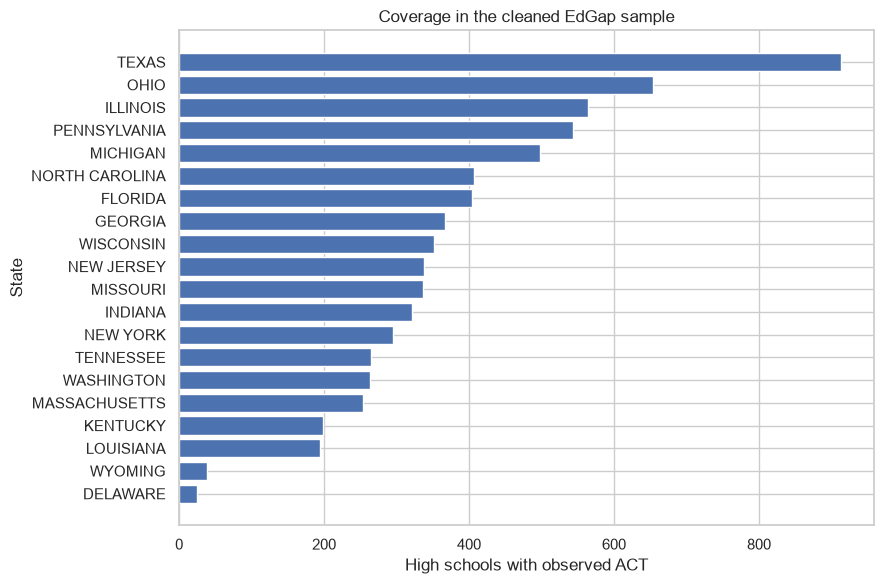

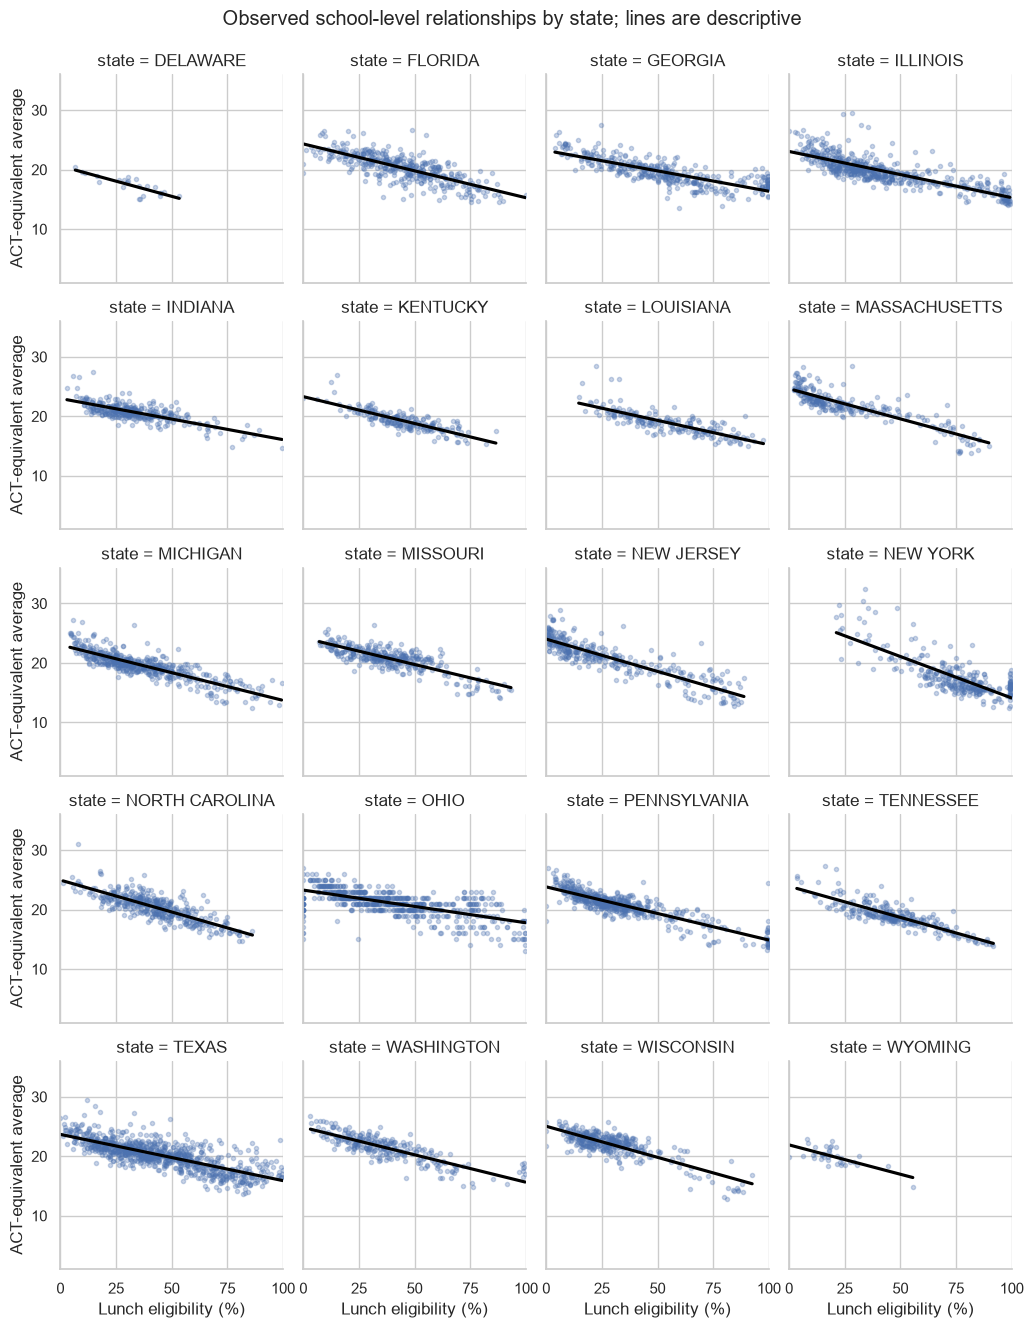

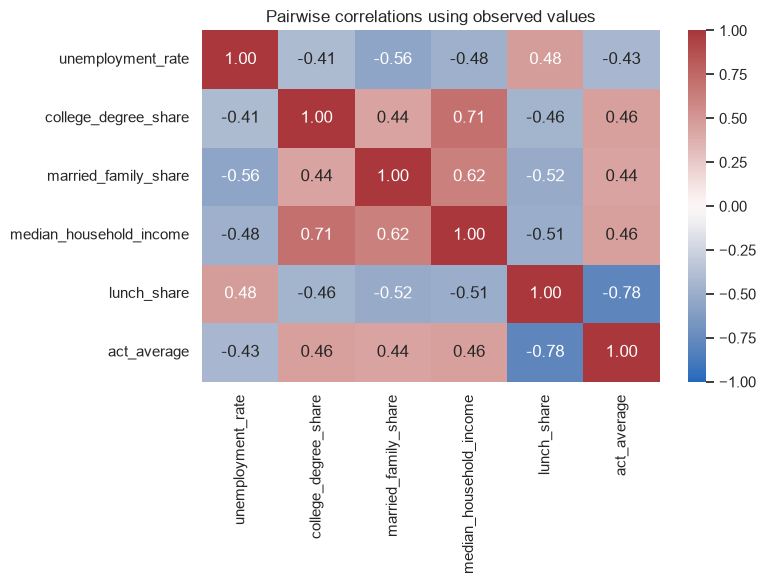

In [6]:
def state_summary(frame):
    rows = []
    for state, group in frame.groupby('state', observed=True):
        pairs = group.dropna(subset=['lunch_share', 'act_average'])
        if len(pairs) < 3:
            correlation, status = np.nan, 'fewer than 3 pairs'
        elif pairs['lunch_share'].nunique() < 2 or pairs['act_average'].nunique() < 2:
            correlation, status = np.nan, 'constant variable'
        else:
            correlation, status = pairs['lunch_share'].corr(pairs['act_average']), 'available'
        rows.append({
            'state': state, 'region': group['region'].iloc[0],
            'schools_with_act': len(group), 'paired_schools': len(pairs),
            'mean_act_paired': pairs['act_average'].mean(),
            'mean_lunch_percent_paired': pairs['lunch_share'].mean() * 100,
            'pearson_r': correlation, 'correlation_status': status,
        })
    return pd.DataFrame(rows).sort_values('state').reset_index(drop=True)

summary = state_summary(observed)
imputed_summary = state_summary(clean)
summary.to_csv(report_dir / 'state_summary_observed.csv', index=False)
imputed_summary.to_csv(report_dir / 'state_summary_imputed.csv', index=False)
sensitivity = summary[['state', 'paired_schools', 'pearson_r']].merge(
    imputed_summary[['state', 'paired_schools', 'pearson_r']], on='state', suffixes=('_observed', '_imputed'), validate='one_to_one',
)
sensitivity['correlation_change'] = sensitivity['pearson_r_imputed'] - sensitivity['pearson_r_observed']
sensitivity.to_csv(report_dir / 'imputation_sensitivity.csv', index=False)
display(summary, sensitivity)
print('States absent from cleaned data:', sorted(set(regions.state) - set(observed.state)))
observed[predictors + ['act_average']].describe().to_csv(report_dir / 'descriptive_statistics.csv')

fig, ax = plt.subplots(figsize=(9, 6))
coverage = summary.sort_values('schools_with_act')
ax.barh(coverage['state'], coverage['schools_with_act'])
ax.set(xlabel='High schools with observed ACT', ylabel='State', title='Coverage in the cleaned EdGap sample')
fig.tight_layout()
fig.savefig(report_dir / 'state_coverage.png', dpi=150)
plt.show()

plot_data = observed.dropna(subset=['lunch_share']).copy()
plot_data['lunch_percent'] = plot_data['lunch_share'] * 100
grid = sns.lmplot(data=plot_data, x='lunch_percent', y='act_average', col='state', col_wrap=4, height=2.6, ci=None, scatter_kws={'s': 9, 'alpha': 0.3}, line_kws={'color': 'black'})
grid.set_axis_labels('Lunch eligibility (%)', 'ACT-equivalent average')
grid.set(xlim=(0, 100), ylim=(1, 36))
grid.figure.suptitle('Observed school-level relationships by state; lines are descriptive', y=1.02)
grid.figure.savefig(report_dir / 'lunch_act_by_state.png', dpi=150, bbox_inches='tight')
plt.show()

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(observed[predictors + ['act_average']].corr(), annot=True, fmt='.2f', vmin=-1, vmax=1, center=0, cmap='vlag', ax=ax)
ax.set_title('Pairwise correlations using observed values')
fig.tight_layout()
fig.savefig(report_dir / 'predictor_correlations.png', dpi=150)
plt.show()


## 6. Interpretation and next steps

Review the state table and plots before writing conclusions:

- Which states have enough paired observations to support a useful comparison?
- Is the direction of association consistent within states? Where does the scatter look different?
- How much do correlations change after imputation?
- What might differences in test participation, reporting, or school composition explain?

The charts do not demonstrate causation or establish statistically significant differences between states. Region labels are context only. A later analysis could examine state-by-lunch interactions while adjusting for the other socioeconomic measures, with an appropriate train/test split if prediction is the goal.

**Sources:** EdGap and NCES school data provided in DATA 5100; Census Bureau state-region reference. See the README for links. Review and revise this notebook yourself before submitting.